In [1]:
# **Logistic Regression**

import pandas as pd

In [2]:
df=pd.read_csv("gender_classification.csv")
df

,long_hair,forehead_width_cm,forehead_height_cm,nose_wide,nose_long,lips_thin,distance_nose_to_lip_long,gender
0,1,11.8,6.1,1,0,1,1,Male
1,0,14.0,5.4,0,0,1,0,Female
2,0,11.8,6.3,1,1,1,1,Male
3,0,14.4,6.1,0,1,1,1,Male
4,1,13.5,5.9,0,0,0,0,Female
...,...,...,...,...,...,...,...,...
4996,1,13.6,5.1,0,0,0,0,Female
4997,1,11.9,5.4,0,0,0,0,Female
4998,1,12.9,5.7,0,0,0,0,Female
4999,1,13.2,6.2,0,0,0,0,Female


In [3]:
# **Data Preprocessing Steps**
# Checking missing values
print("Missing values:\n", df.isnull().sum())


Missing values:
 long_hair                    0
forehead_width_cm            0
forehead_height_cm           0
nose_wide                    0
nose_long                    0
lips_thin                    0
distance_nose_to_lip_long    0
gender                       0
dtype: int64


In [4]:
# Check Duplicate Rows
print("\nDuplicate rows:", df.duplicated().sum())


Duplicate rows: 1768


In [5]:
#code for dropping duplicating value
df = df.drop_duplicates()


In [6]:
#rechecking duplicate values
print("\nDuplicate rows:", df.duplicated().sum())



Duplicate rows: 0


In [7]:
pip install scikit-learn


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.7/8.7 MB 6.4 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 306.1/306.1 kB 6.8 MB/s eta 0:00:00a 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 22.4/22.4 MB 9.1 MB/s eta 0:00:0000:0100:01

[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [8]:
# Preprocessing
from sklearn.preprocessing import LabelEncoder
# Encode gender (Male=1, Female=0)
le = LabelEncoder()
df["gender"] = le.fit_transform(df["gender"])

X = df.drop("gender", axis=1)
y = df["gender"]

/var/folders/47/l143_1250w94rg70kb7bcg_h0000gn/T/ipykernel_42845/2776381951.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["gender"] = le.fit_transform(df["gender"])


In [9]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [10]:

# **Model Training**

from sklearn.linear_model import LogisticRegression
# Logistic Regression

log_reg = LogisticRegression()
log_reg.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [11]:
# **Model Evaluation**
from sklearn.metrics import accuracy_score, classification_report

# Logistic Regression
y_pred_log = log_reg.predict(X_test)
print("\nLogistic Regression Results")
print("Accuracy:", accuracy_score(y_test, y_pred_log))
print(classification_report(y_test, y_pred_log, target_names=["Female","Male"]))
#Conclusion: Logistic Regression is performing very well (~96% accuracy) and predicts both Male and Female reliably.**



Logistic Regression Results
Accuracy: 0.9556701030927836
              precision    recall  f1-score   support

      Female       0.96      0.95      0.95       457
        Male       0.96      0.96      0.96       513

    accuracy                           0.96       970
   macro avg       0.96      0.96      0.96       970
weighted avg       0.96      0.96      0.96       970



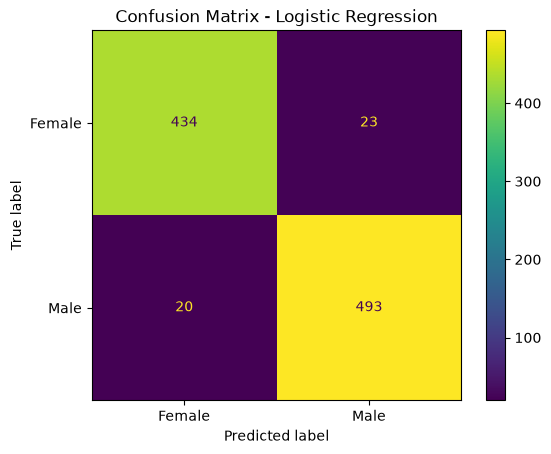

In [13]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred_log)

# Display confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Female", "Male"])
disp.plot()
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

In [12]:
#External Prediction

new_data = [[0, 13.5, 6.2, 1, 1, 0, 1]] 

# Column names must match training data
new_data_df = pd.DataFrame(new_data, columns=X.columns)

# Predict again
log_result = log_reg.predict(new_data_df)[0]


print("Logistic Regression:", le.inverse_transform([log_result])[0])

#This means, based on the features you provided (long_hair=0, forehead_width=13.5, forehead_height=6.2, nose_wide=1, nose_long=1, lips_thin=0, distance_nose_to_lip_long=1), the models agree that the person is most likely male.

Logistic Regression: Male
